# HandPD: EfficientNetB0 Transfer Learning (Spiral + Meander fusion)
- Backbone එක **එකයි** (Spiral සහ Meander දෙකටම weights share)
- Phase 1: backbone freeze කරලා head එක train → Phase 2: backbone ගේ අන්තිම layers fine-tune
- කලින් custom model එකේ **එකම folds** (SEED=42, subject-wise) → ප්‍රතිඵල සෘජුවම සසඳන්න පුළුවන්
- ImageNet weights පළමු වතාවට download වෙන්න **internet** ඕනේ (~20MB)

In [7]:
import os, re, glob, json, time, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# ---------- PATHS (හැමදේම මේ අලුත් folder එක ඇතුළේ) ----------
ROOT = Path.cwd()                                 # notebook එක තියෙන folder එක
ZIP_PATH = ROOT / "../handpd_dataset.zip"            # zip file එක මේ folder එකටම copy කරන්න
DATA_DIR = ROOT / "../data"                          # auto extract වෙනවා
TL_DIR = ROOT / "../model"                           # models + config save වෙන තැන (auto හැදෙනවා)

# කලින් custom CNN එකේ oof_results.npz path එක (සසඳන්න ඕන නම් පමණයි), නැත්නම් None තියන්න
OLD_RESULTS = None   # උදා: Path(r"C:\Users\kanis\Desktop\model\...\model\oof_results.npz")

TL_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
print("ROOT:", ROOT)

# ---------- SETTINGS ----------
IMG_SIZE = 224            # CPU එක ගොඩක් මන්දගාමී නම් 160 කරන්න
BATCH = 16
N_FOLDS = 5
SEED = 42
FOLDS_TO_RUN = list(range(N_FOLDS))    # [3] දැම්මොත් Fold 4 විතරක් (ඉක්මන් test එකක්)

PHASE1_EPOCHS, LR1 = 8, 1e-3           # backbone frozen
PHASE2_EPOCHS, LR2 = 15, 1e-4          # fine-tune
UNFREEZE_LAYERS = 40                   # backbone ගේ අන්තිම layers කීයක් fine-tune කරන්නද

tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPUs:", gpus if gpus else "නෑ (CPU)")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

ROOT: c:\Users\kanis\Desktop\model\transfer learning\notebook
TensorFlow: 2.22.0-rc0
GPUs: නෑ (CPU)


## 1. Dataset (unzip + folders)

In [8]:
def has_dataset(base):
    return any(os.path.basename(r) == "SpiralPatients" for r, _, _ in os.walk(base))

if not has_dataset(DATA_DIR):
    assert ZIP_PATH.exists(), f"Zip file එක හම්බුණේ නෑ. handpd_dataset.zip මේ folder එකට දාන්න: {ROOT}"
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Unzip කළා.")
else:
    print("කලින්ම unzip කරලා තියෙනවා.")

def find_dir(name):
    hits = [r for r, _, _ in os.walk(DATA_DIR) if os.path.basename(r) == name]
    assert hits, f"{name} folder එක හම්බුණේ නෑ"
    return hits[0]

dirs = {n: find_dir(n) for n in
        ["SpiralPatients", "SpiralControl", "MeanderPatients", "MeanderControl"]}

def list_imgs(d):
    fs = set()
    for e in ("*.jpg", "*.jpeg", "*.png", "*.bmp"):
        fs.update(glob.glob(os.path.join(d, e)))
    return sorted(fs)

Unzip කළා.


## 2. Pairing (Meander = Spiral + 4), කලින් වගේම

In [9]:
def parse_name(fpath):
    m = re.match(r"^(\d+)-(\d+)", os.path.basename(fpath))
    assert m, f"Filename parse කරන්න බැරි වුණා: {fpath}"
    return m.group(1), int(m.group(2))

def build_pairs(spiral_dir, meander_dir, label):
    sp_map = {parse_name(f): f for f in list_imgs(spiral_dir)}
    me_map = {parse_name(f): f for f in list_imgs(meander_dir)}
    prefix = "P" if label == 1 else "H"
    rows, missing = [], 0
    for (sid, n), sp_path in sorted(sp_map.items()):
        key = (sid, n + 4)
        if key in me_map:
            rows.append((sp_path, me_map[key], label, f"{prefix}{sid}"))
        else:
            missing += 1
    print(f"label={label}: pairs={len(rows)}, unmatched spiral={missing}")
    return rows

rows = build_pairs(dirs["SpiralPatients"], dirs["MeanderPatients"], 1) + \
       build_pairs(dirs["SpiralControl"],  dirs["MeanderControl"],  0)

df = pd.DataFrame(rows, columns=["spiral", "meander", "label", "subject"])
print(df.shape, df.label.value_counts().to_dict())
print("subjects:", df.groupby("label").subject.nunique().to_dict())

label=1: pairs=296, unmatched spiral=0
label=0: pairs=72, unmatched spiral=0
(368, 4) {1: 296, 0: 72}
subjects: {0: 18, 1: 74}


## 3. Images load කිරීම
EfficientNet එකට **RGB, 0-255** ඕනේ (normalization එක model එක ඇතුළේම තියෙනවා).
Pretrained features වලට ගැලපෙන්න **මුල් images** (සුදු කඩදාසිය, කළු ඉරි) භාවිතා කරනවා, invert කරන්නේ නෑ.

(368, 224, 224, 3) (368, 224, 224, 3) uint8 (368,)


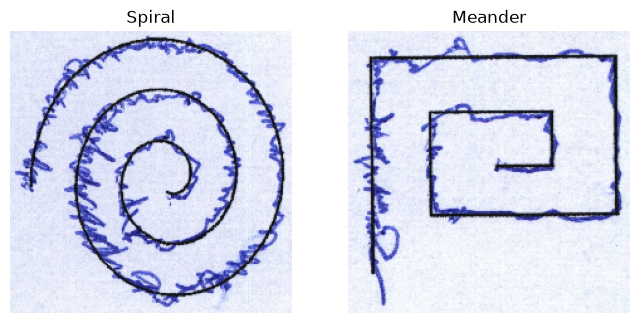

In [10]:
def load_rgb(path):
    img = tf.keras.utils.load_img(path, color_mode="rgb", target_size=(IMG_SIZE, IMG_SIZE))
    return np.asarray(img, dtype="uint8")

X_sp = np.stack([load_rgb(p) for p in df.spiral])
X_me = np.stack([load_rgb(p) for p in df.meander])
y_all = df.label.values.astype("float32")
print(X_sp.shape, X_me.shape, X_sp.dtype, y_all.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(X_sp[0]); ax[0].set_title("Spiral"); ax[0].axis("off")
ax[1].imshow(X_me[0]); ax[1].set_title("Meander"); ax[1].axis("off")
plt.show()

## 4. tf.data + augmentation + model

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

# පසුබිම සුදු නිසා fill_value=255
augment = tf.keras.Sequential([
    layers.RandomRotation(0.05, fill_mode="constant", fill_value=255.0),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=255.0),
    layers.RandomZoom(0.1, fill_mode="constant", fill_value=255.0),
])

def cast_pair(x, y):
    a, b = x
    return (tf.cast(a, tf.float32), tf.cast(b, tf.float32)), y

def aug_pair(x, y):
    a, b = x
    return (augment(a, training=True), augment(b, training=True)), y

def make_ds(idx, training):
    ds = tf.data.Dataset.from_tensor_slices(((X_sp[idx], X_me[idx]), y_all[idx]))
    if training:
        ds = ds.shuffle(len(idx), seed=SEED)
    ds = ds.map(cast_pair, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(aug_pair, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

def build_model():
    backbone = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    backbone.trainable = False

    sp_in = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="spiral_input")
    me_in = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="meander_input")

    def features(x):
        f = backbone(x, training=False)          # BN සහ drop_connect inference mode එකේ (small data එකට ස්ථායියි)
        return layers.Concatenate()([layers.GlobalAveragePooling2D()(f),
                                     layers.GlobalMaxPooling2D()(f)])

    x = layers.Concatenate()([features(sp_in), features(me_in)])   # එකම backbone එක දෙපාරක්
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return models.Model([sp_in, me_in], out, name="effnet_fusion"), backbone

def compile_model(m, lr, steps, epochs):
    sched = tf.keras.optimizers.schedules.CosineDecay(lr, steps * epochs)
    m.compile(optimizer=tf.keras.optimizers.Adam(sched, clipnorm=1.0),
              loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

def unfreeze_top(backbone, n_layers):
    backbone.trainable = True
    for l in backbone.layers[:-n_layers]:
        l.trainable = False
    for l in backbone.layers:                    # BatchNorm සැමවිටම frozen
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False

m_test, b_test = build_model()
m_test.summary()
print("backbone layers:", len(b_test.layers))
del m_test, b_test

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 127s 8us/step


Model: "effnet_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ spiral_input        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meander_input       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ spiral_input[0][… │
│ (Functional)        │ 1280)             │            │ meander_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 2560)      │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 2560)      │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 5120)      │          0 │ concatenate_1[0]… │
│ (Concatenate)       │                   │            │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 5120)      │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │    327,744 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,377,380 (16.70 MB)

 Trainable params: 327,809 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

backbone layers: 238


## 5. Stratified Group 5-Fold CV (කලින් custom model එකේ folds ම)
Models `model/fold*.keras` ලෙස save වෙනවා (මේ folder එක ඇතුළේ).

In [14]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve

def logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    t = thr[np.argmax(tpr - fpr)]
    return float(np.clip(t, 1e-6, 1 - 1e-6))

def make_log(tag, total):
    return tf.keras.callbacks.LambdaCallback(
        on_epoch_end=lambda e, l: print(
            f"  [{tag}] epoch {e+1:>2}/{total} loss={l['loss']:.3f} auc={l['auc']:.3f}")
        if ((e + 1) % 5 == 0 or e + 1 == total) else None)

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(sgkf.split(df, df.label, groups=df.subject))

oof_prob  = np.zeros(len(df))
oof_score = np.zeros(len(df))
oof_fold  = np.zeros(len(df), dtype=int)     # 0 = මේ fold එක තාම run කරලා නෑ
fold_thr, fold_aucs = {}, {}

for fold in FOLDS_TO_RUN:
    tr, te = folds[fold]
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold)
    t0 = time.time()

    n0 = (y_all[tr] == 0).sum(); n1 = (y_all[tr] == 1).sum()
    cw = {0: len(tr) / (2 * n0), 1: len(tr) / (2 * n1)}
    steps = int(np.ceil(len(tr) / BATCH))

    model, backbone = build_model()

    # Phase 1: backbone frozen
    compile_model(model, LR1, steps, PHASE1_EPOCHS)
    model.fit(make_ds(tr, True), epochs=PHASE1_EPOCHS, class_weight=cw, verbose=2,
              callbacks=[make_log("P1", PHASE1_EPOCHS)])

    # Phase 2: අන්තිම layers fine-tune
    unfreeze_top(backbone, UNFREEZE_LAYERS)
    compile_model(model, LR2, steps, PHASE2_EPOCHS)
    model.fit(make_ds(tr, True), epochs=PHASE2_EPOCHS, class_weight=cw, verbose=2,
              callbacks=[make_log("P2", PHASE2_EPOCHS)])

    p_tr = model.predict(make_ds(tr, False), verbose=2).ravel()
    p_te = model.predict(make_ds(te, False), verbose=2).ravel()

    thr = youden_threshold(y_all[tr], p_tr)
    oof_prob[te]  = p_te
    oof_score[te] = logit(p_te) - logit(thr)
    oof_fold[te]  = fold + 1
    fold_thr[fold + 1] = thr

    auc_tr = roc_auc_score(y_all[tr], p_tr)
    auc_te = roc_auc_score(y_all[te], p_te)
    fold_aucs[fold + 1] = auc_te
    print(f"Fold {fold+1}: train_AUC={auc_tr:.3f} | test_AUC={auc_te:.3f} | thr={thr:.3f} | "
          f"mean prob control={p_te[y_all[te]==0].mean():.3f} patient={p_te[y_all[te]==1].mean():.3f} | "
          f"{time.time()-t0:.0f}s")

    model.save(TL_DIR / f"fold{fold+1}.keras")
    np.savez(TL_DIR / "oof_results.npz", oof_prob=oof_prob, oof_score=oof_score, oof_fold=oof_fold,
             fold_ids=np.array(list(fold_thr.keys())), fold_thr=np.array(list(fold_thr.values())),
             fold_aucs=np.array(list(fold_aucs.values())))

vals = list(fold_aucs.values())
print("\nFold AUC mean ± std:", round(float(np.mean(vals)), 3), "±", round(float(np.std(vals)), 3))
done = oof_fold > 0
print("OOF AUC (raw prob)         :", round(roc_auc_score(y_all[done], oof_prob[done]), 3))
print("OOF AUC (normalized score) :", round(roc_auc_score(y_all[done], oof_score[done]), 3))

c:\Users\kanis\Desktop\model\transfer learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  [P1] epoch  5/8 loss=0.332 auc=0.942
  [P1] epoch  8/8 loss=0.238 auc=0.967
  [P2] epoch  5/15 loss=0.180 auc=0.980
  [P2] epoch 10/15 loss=0.061 auc=0.996
  [P2] epoch 15/15 loss=0.044 auc=1.000
Fold 1: train_AUC=0.993 | test_AUC=0.910 | thr=0.947 | mean prob control=0.523 patient=0.967 | 414s


c:\Users\kanis\Desktop\model\transfer learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  [P1] epoch  5/8 loss=0.446 auc=0.900
  [P1] epoch  8/8 loss=0.282 auc=0.950
  [P2] epoch  5/15 loss=0.237 auc=0.969
  [P2] epoch 10/15 loss=0.082 auc=0.996
  [P2] epoch 15/15 loss=0.056 auc=0.999
Fold 2: train_AUC=0.994 | test_AUC=0.910 | thr=0.957 | mean prob control=0.804 patient=0.983 | 427s


c:\Users\kanis\Desktop\model\transfer learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  [P1] epoch  5/8 loss=0.641 auc=0.842
  [P1] epoch  8/8 loss=0.305 auc=0.947
  [P2] epoch  5/15 loss=0.203 auc=0.976
  [P2] epoch 10/15 loss=0.164 auc=0.986
  [P2] epoch 15/15 loss=0.091 auc=0.997
Fold 3: train_AUC=0.989 | test_AUC=0.957 | thr=0.967 | mean prob control=0.638 patient=0.979 | 405s


c:\Users\kanis\Desktop\model\transfer learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  [P1] epoch  5/8 loss=0.239 auc=0.965
  [P1] epoch  8/8 loss=0.267 auc=0.961
  [P2] epoch  5/15 loss=0.146 auc=0.988
  [P2] epoch 10/15 loss=0.071 auc=0.998
  [P2] epoch 15/15 loss=0.047 auc=1.000
Fold 4: train_AUC=0.998 | test_AUC=0.800 | thr=0.929 | mean prob control=0.883 patient=0.969 | 418s


c:\Users\kanis\Desktop\model\transfer learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  [P1] epoch  5/8 loss=0.557 auc=0.847
  [P1] epoch  8/8 loss=0.481 auc=0.889
  [P2] epoch  5/15 loss=0.338 auc=0.947
  [P2] epoch 10/15 loss=0.175 auc=0.990
  [P2] epoch 15/15 loss=0.141 auc=0.997
Fold 5: train_AUC=0.982 | test_AUC=0.950 | thr=0.846 | mean prob control=0.628 patient=0.970 | 472s

Fold AUC mean ± std: 0.906 ± 0.056
OOF AUC (raw prob)         : 0.893
OOF AUC (normalized score) : 0.896


## 6. Final metrics (score > 0 = Patient)

In [15]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score)

done = oof_fold > 0
yt, sc = y_all[done], oof_score[done]
pred = (sc > 0).astype(int)
print(confusion_matrix(yt, pred))
print(classification_report(yt, pred, target_names=["Control", "Patient"], zero_division=0))
print("Balanced accuracy:", round(balanced_accuracy_score(yt, pred), 3))
print("Macro F1         :", round(f1_score(yt, pred, average="macro"), 3))

for f in sorted(fold_aucs):
    m = oof_fold == f
    y, s = y_all[m], oof_score[m]
    print(f"Fold {f}: AUC={roc_auc_score(y, s):.3f} | control සාර්ථක={((s<=0)&(y==0)).sum()}/{(y==0).sum()} | "
          f"patient සාර්ථක={((s>0)&(y==1)).sum()}/{(y==1).sum()}")

# කලින් අමාරු control පුද්ගලයන් 3 දෙනා
hard = df[(df.subject.isin(["H0287", "H0297", "H0305"])) & done]
if len(hard):
    print("\nකලින් අමාරු subjects (custom CNN scores: H0287≈-0.1~+0.7, H0297≈+2~+5, H0305≈+7~+9):")
    print(pd.Series(oof_score[hard.index], index=hard.subject).groupby(level=0).mean().round(2))

[[ 50  22]
 [ 26 270]]
              precision    recall  f1-score   support

     Control       0.66      0.69      0.68        72
     Patient       0.92      0.91      0.92       296

    accuracy                           0.87       368
   macro avg       0.79      0.80      0.80       368
weighted avg       0.87      0.87      0.87       368

Balanced accuracy: 0.803
Macro F1         : 0.797
Fold 1: AUC=0.910 | control සාර්ථක=12/16 | patient සාර්ථක=52/60
Fold 2: AUC=0.910 | control සාර්ථක=11/16 | patient සාර්ථක=54/60
Fold 3: AUC=0.957 | control සාර්ථක=11/12 | patient සාර්ථක=54/60
Fold 4: AUC=0.800 | control සාර්ථක=4/12 | patient සාර්ථක=57/60
Fold 5: AUC=0.950 | control සාර්ථක=12/16 | patient සාර්ථක=53/56

කලින් අමාරු subjects (custom CNN scores: H0287≈-0.1~+0.7, H0297≈+2~+5, H0305≈+7~+9):
subject
H0287   -1.29
H0297    1.67
H0305    5.91
dtype: float64


## 7. Custom CNN එක සමඟ සංසන්දනය (කලින් oof_results.npz තියෙනවා නම්)

In [16]:
old_path = Path(OLD_RESULTS) if OLD_RESULTS else None
if old_path is not None and old_path.exists():
    old = np.load(old_path)
    both = (oof_fold > 0)
    print("Custom CNN OOF AUC (score):", round(roc_auc_score(y_all[both], old["oof_score"][both]), 3))
    print("EfficientNet OOF AUC (score):", round(roc_auc_score(y_all[both], oof_score[both]), 3))
    for name, s in [("Custom CNN", old["oof_score"]), ("EfficientNet", oof_score)]:
        p = (s[both] > 0).astype(int)
        print(f"{name:13s} balanced acc={balanced_accuracy_score(y_all[both], p):.3f} "
              f"macro F1={f1_score(y_all[both], p, average='macro'):.3f}")
else:
    print("OLD_RESULTS path එක දාලා නෑ (හෝ file එක නෑ), සංසන්දනය මඟහරිනවා. ඒක අවශ්‍ය නම් Cell 1 හි OLD_RESULTS සකසන්න.")

OLD_RESULTS path එක දාලා නෑ (හෝ file එක නෑ), සංසන්දනය මඟහරිනවා. ඒක අවශ්‍ය නම් Cell 1 හි OLD_RESULTS සකසන්න.


## 8. Config save + අලුත් images වලට predict (fold ensemble)

In [17]:
config = {"img_size": IMG_SIZE, "backbone": "EfficientNetB0",
          "fold_thresholds": {str(k): v for k, v in fold_thr.items()},
          "label_map": {"0": "Control", "1": "Patient"},
          "note": "score = mean_k(logit(p_k) - logit(thr_k)); score > 0 => Patient"}
with open(TL_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

def predict_pair(spiral_path, meander_path):
    cfg = json.load(open(TL_DIR / "config.json"))
    size = cfg["img_size"]

    def prep(p):
        img = tf.keras.utils.load_img(p, color_mode="rgb", target_size=(size, size))
        return np.asarray(img, dtype="float32")[None]

    xs, xm = prep(spiral_path), prep(meander_path)
    scores = []
    for k, thr in cfg["fold_thresholds"].items():
        m = tf.keras.models.load_model(TL_DIR / f"fold{k}.keras")
        p = float(m.predict([xs, xm], verbose=0).ravel()[0])
        scores.append(float(logit(np.array(p)) - logit(np.array(thr))))
    s = float(np.mean(scores))
    return {"score": s, "prediction": "Patient" if s > 0 else "Control"}

print(predict_pair(df.spiral[0], df.meander[0]), "| true label:", int(df.label[0]))

{'score': 11.703995843858053, 'prediction': 'Patient'} | true label: 1
